# Tara Oceans in ENA: what was sequenced, on which instruments, and how findable is it?

**Module 02.1 · my implementation** — Seid Adem

**Tara Oceans** (2009–2013) was a schooner expedition that sampled plankton across the world's oceans, from viruses to
small animals, by filtering seawater into **size fractions** at defined depths. Its sequencing data are archived in the
**European Nucleotide Archive (ENA)** under the umbrella project **PRJEB402**.

The course practical used the ENA Portal API to find the raw files behind *one* small MGnify study (ISS dust). This
notebook applies the same API to a whole flagship project and asks:

1. What kinds of sequencing were done, and how much?
2. Which instruments produced the data?
3. How many reads does a run contain, and what explains the spread?
4. When did data become public, relative to when samples were collected?
5. Where, and from which depths and size fractions, were samples taken?
6. How complete and machine-readable is the metadata (the **F** and **I** of FAIR)?

Tools: [`dsls.ena`](../../../src/dsls/ena.py) (unit-tested in [`tests/test_ena.py`](../../../tests/test_ena.py)) on top of
my cached API client [`dsls.ebi_api`](../../../src/dsls/ebi_api.py).

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from dsls.ebi_api import ena_portal
from dsls.ena import assay_type, completeness, fetch_runs, fetch_samples, is_placeholder

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PROJECT = "PRJEB402"  # Tara Oceans umbrella project

## 1 · Retrieve the run table

One request returns every run (`limit=0`). `fetch_runs` compares the row count with ENA's `/count` endpoint and raises an
error if they differ. ENA has no numbered releases, so the retrieval date recorded in the cache metadata
(`data/raw/api_cache/ena/`) is the version stamp.

In [2]:
runs = fetch_runs(PROJECT)
runs["assay"] = [
    assay_type(s, src) for s, src in zip(runs["library_strategy"], runs["library_source"], strict=True)
]
runs["Gbp"] = runs["base_count"] / 1e9

studies = (
    runs.groupby(["study_accession", "study_title"])
    .agg(runs=("run_accession", "size"), Gbp=("Gbp", "sum"))
    .sort_values("runs", ascending=False)
    .reset_index()
)
print(
    f"{PROJECT}: {len(runs):,} runs in {runs['study_accession'].nunique()} sub-studies, "
    f"{runs['sample_accession'].nunique():,} samples, {runs['base_count'].sum() / 1e12:.1f} Tbp, "
    f"{runs['fastq_bytes'].sum() / 1e12:.1f} TB of compressed FASTQ"
)
studies.round(0)

PRJEB402: 6,423 runs in 22 sub-studies, 1,940 samples, 77.4 Tbp, 66.1 TB of compressed FASTQ


,study_accession,study_title,runs,Gbp
0,PRJEB6610,Amplicon sequencing of Tara Oceans DNA samples...,2269,988.0
1,PRJEB4352,Shotgun Sequencing of Tara Oceans DNA samples ...,1075,31077.0
2,PRJEB6609,Metatranscriptome sequencing from samples corr...,860,16412.0
3,PRJEB6608,Metatranscriptome sequencing of Tara Oceans DN...,465,4422.0
4,PRJEB9737,Amplicon sequencing of Tara Oceans Polar Circl...,369,259.0
5,PRJEB9738,Metatranscriptome sequencing from Tara Oceans ...,253,5696.0
6,PRJEB1787,Shotgun Sequencing of Tara Oceans DNA samples ...,249,4930.0
7,PRJEB4419,Shotgun Sequencing of Tara Oceans DNA samples ...,140,1826.0
8,PRJEB9691,Shotgun Sequencing of Tara Oceans Polar Circle...,120,4418.0
9,PRJEB36282,Amplicon sequencing of Tara Oceans DNA samples...,107,29.0


## 2 · Q1 — What was sequenced?

In [3]:
by_assay = (
    runs.groupby("assay")
    .agg(
        runs=("run_accession", "size"),
        samples=("sample_accession", "nunique"),
        Tbp=("Gbp", lambda g: g.sum() / 1e3),
    )
    .sort_values("Tbp", ascending=False)
)
by_assay["share_of_runs"] = by_assay["runs"] / by_assay["runs"].sum()
by_assay["share_of_bases"] = by_assay["Tbp"] / by_assay["Tbp"].sum()
by_assay.style.format({"Tbp": "{:.1f}", "share_of_runs": "{:.0%}", "share_of_bases": "{:.0%}"})

,runs,samples,Tbp,share_of_runs,share_of_bases
assay,,,,,
Metagenome,1730,1271,45.6,27%,59%
Metatranscriptome,1703,804,28.0,27%,36%
Single-cell genome (WGA),151,118,2.5,2%,3%
Amplicon (marker gene),2839,1325,1.3,44%,2%


## 3 · Q2 — Which instruments produced the data?

,runs,Tbp
instrument_model,,
Illumina HiSeq 2000,3289,70.7
Illumina HiSeq 2500,1692,5.0
Illumina Genome Analyzer IIx,1258,0.9
unspecified,48,0.3
Illumina HiSeq 4000,16,0.2
Illumina NovaSeq 6000,2,0.2
454 GS FLX Titanium,99,0.0
Illumina MiSeq,19,0.0


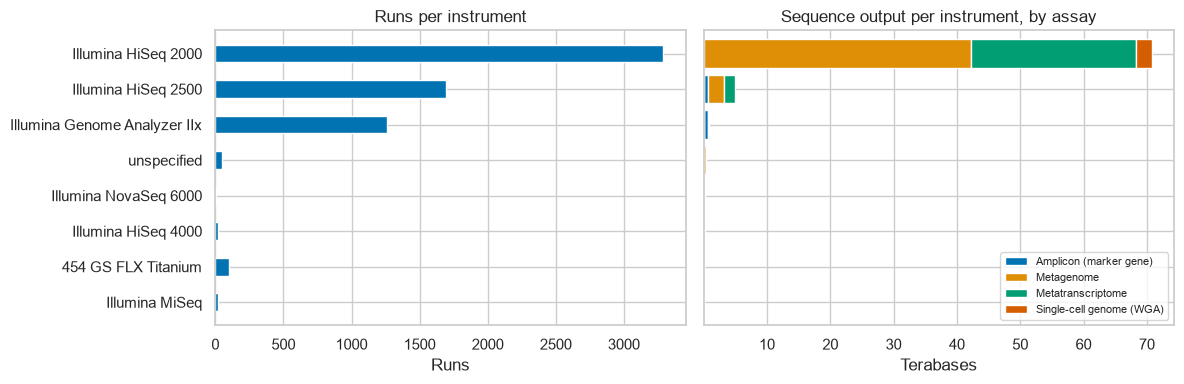

In [4]:
INSTRUMENT_ORDER = (
    runs.groupby("instrument_model")["first_public"].min().sort_values().index.tolist()
)  # roughly chronological
inst = runs.pivot_table(index="instrument_model", columns="assay", values="Gbp", aggfunc="sum", fill_value=0)
inst = inst.loc[inst.sum(axis=1).sort_values().index] / 1e3  # Tbp
inst_runs = runs["instrument_model"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
inst_runs.reindex(inst.index).plot.barh(ax=axes[0], color=sns.color_palette("colorblind")[0])
axes[0].set(xlabel="Runs", ylabel="", title="Runs per instrument")
inst.plot.barh(stacked=True, ax=axes[1], color=sns.color_palette("colorblind"), width=0.8)
axes[1].set(xlabel="Terabases", title="Sequence output per instrument, by assay")
axes[1].legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "ena_01_instruments.png", dpi=150)
pd.DataFrame({"runs": inst_runs, "Tbp": inst.sum(axis=1).round(1)}).sort_values("Tbp", ascending=False)

## 4 · Q3 — How many reads does a run contain?

Read counts span five orders of magnitude, so they are plotted on a log scale. Mean read length (bases ÷ reads,
both mates for paired runs) separates the technologies.

,runs,median_reads_M,p10_reads_M,p90_reads_M
assay,,,,
Amplicon (marker gene),2839,1.56,0.61,3.09
Metagenome,1730,163.83,32.67,327.82
Metatranscriptome,1703,74.64,20.90,202.03
Single-cell genome (WGA),151,37.05,20.75,182.30


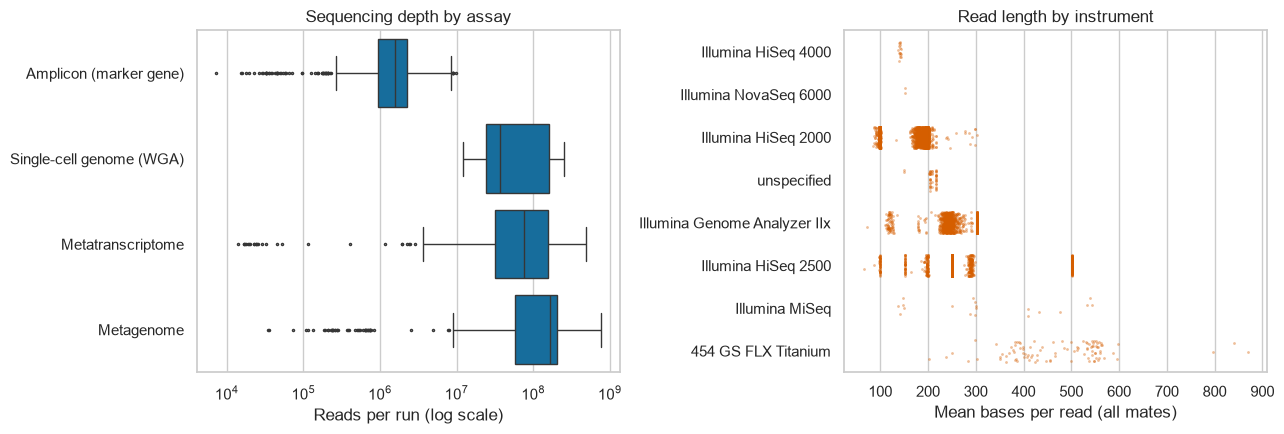

In [5]:
runs["bases_per_read"] = runs["base_count"] / runs["read_count"]
summary = runs.groupby("assay").agg(
    runs=("read_count", "size"),
    median_reads_M=("read_count", lambda r: r.median() / 1e6),
    p10_reads_M=("read_count", lambda r: r.quantile(0.1) / 1e6),
    p90_reads_M=("read_count", lambda r: r.quantile(0.9) / 1e6),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = summary.sort_values("median_reads_M").index
sns.boxplot(
    data=runs,
    y="assay",
    x="read_count",
    order=order,
    ax=axes[0],
    log_scale=True,
    fliersize=1.5,
    color=sns.color_palette("colorblind")[0],
)
axes[0].set(xlabel="Reads per run (log scale)", ylabel="", title="Sequencing depth by assay")
sns.stripplot(
    data=runs,
    y="instrument_model",
    x="bases_per_read",
    ax=axes[1],
    size=2,
    alpha=0.4,
    jitter=0.25,
    order=runs.groupby("instrument_model")["bases_per_read"].median().sort_values().index,
    color=sns.color_palette("colorblind")[3],
)
axes[1].set(xlabel="Mean bases per read (all mates)", ylabel="", title="Read length by instrument")
fig.tight_layout()
fig.savefig(FIGURES / "ena_02_read_counts.png", dpi=150)
summary.round(2)

In [6]:
low = runs[runs["read_count"] < 100_000]
print(f"{len(low)} runs have < 100k reads; by assay: {low['assay'].value_counts().to_dict()}")
print(f"library layout: {runs['library_layout'].value_counts().to_dict()}")

57 runs have < 100k reads; by assay: {'Amplicon (marker gene)': 36, 'Metatranscriptome': 18, 'Metagenome': 3}
library layout: {'PAIRED': 6322, 'SINGLE': 101}


## 5 · Q4 — When did the data become public?

`first_public` is the date a run was released. Collection dates are **not** in ENA's structured fields for this
project (see Q6), so they are parsed from the sample descriptions in section 6 and used here to measure the delay
from sampling to public data.

year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2025
instrument_model,,,,,,,,,,,
454 GS FLX Titanium,51,48,0,0,0,0,0,0,0,0,0
Illumina HiSeq 2000,34,596,206,1337,0,79,525,263,249,0,0
unspecified,48,0,0,0,0,0,0,0,0,0,0
Illumina Genome Analyzer IIx,0,390,0,508,290,0,0,0,0,0,70
Illumina MiSeq,0,7,0,0,0,0,6,0,2,1,3
Illumina HiSeq 2500,0,0,0,0,1,36,229,157,169,1100,0
Illumina NovaSeq 6000,0,0,0,0,0,0,0,2,0,0,0
Illumina HiSeq 4000,0,0,0,0,0,0,0,0,16,0,0


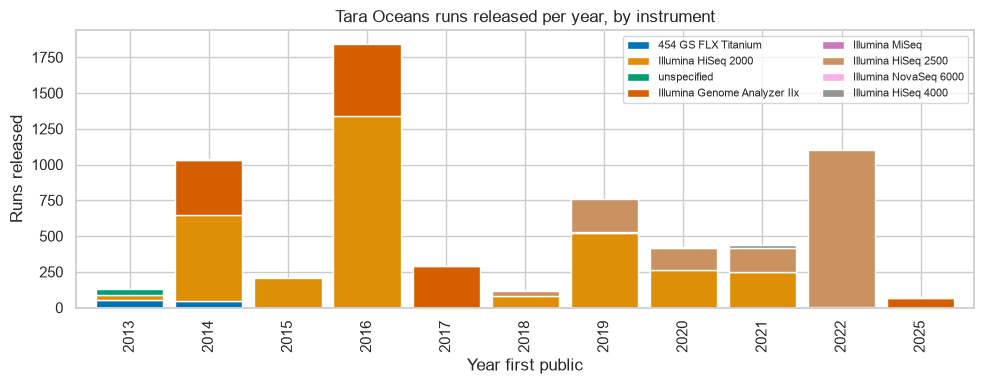

In [7]:
release = runs.assign(year=runs["first_public"].dt.year).pivot_table(
    index="year", columns="instrument_model", values="run_accession", aggfunc="size", fill_value=0
)
release = release[[c for c in INSTRUMENT_ORDER if c in release.columns]]
fig, ax = plt.subplots(figsize=(10, 4))
release.plot.bar(stacked=True, ax=ax, width=0.85, color=sns.color_palette("colorblind", len(release.columns)))
ax.set(
    xlabel="Year first public",
    ylabel="Runs released",
    title="Tara Oceans runs released per year, by instrument",
)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "ena_03_release_timeline.png", dpi=150)
release.T

## 6 · Q5 — Where, when, and from which water layers and size fractions?

ENA returns only 448 samples when searched by project, but the runs reference 1,940. `fetch_samples` looks all of them up
by accession instead. Station, date, depth layer and size fraction are in **free-text descriptions** in two different
formats, so they're parsed with regular expressions and the parse rate is reported. Unparsed values are not guessed.

In [8]:
samples = fetch_samples(runs["sample_accession"].dropna().unique().tolist())
by_project = int(
    ena_portal()
    .get("count", {"result": "sample", "query": f"study_accession={PROJECT}"}, accept="text/plain")
    .text.split()[-1]
)
print(f"samples referenced by runs: {len(samples):,}; samples found by searching the project: {by_project:,}")
desc = samples["description"].fillna("")

# Format A: "...at station TARA_064 ... on date/time=2010-07-07T07:53 ... size-fractionated (20-180 micrometres)..."
a = pd.DataFrame(
    {
        "station": desc.str.extract(r"station (TARA_\d+)")[0],
        "date": desc.str.extract(r"date/time=(\d{4}-\d{2}-\d{2})")[0],
        "fraction": desc.str.extract(r"size-fractionated \(([^)]*?) ?micrometres\)")[0],
        "layer": desc.str.extract(
            r"(surface water layer|deep chlorophyll maximum layer|mesopelagic zone|epipelagic mixed layer)"
        )[0],
    }
)
# Format B: "Station30 - Deep Chlorophyl Maximum - 20-180 µm - DNA"
b = desc.str.extract(r"^Station(?P<num>\d+) - (?P<layer>[^-]+?) - (?P<fraction>[\d.]+-[\d.>]*) ?µm")
a["station"] = a["station"].fillna(b["num"].map(lambda n: f"TARA_{int(n):03d}" if pd.notna(n) else n))
a["fraction"] = a["fraction"].fillna(b["fraction"])
a["layer"] = a["layer"].fillna(b["layer"])
LAYER = {
    "surface water layer": "SRF (surface)",
    "Surface": "SRF (surface)",
    "deep chlorophyll maximum layer": "DCM (deep chlorophyll max.)",
    "Deep Chlorophyl Maximum": "DCM (deep chlorophyll max.)",
    "mesopelagic zone": "MES (mesopelagic)",
    "Mesopelagic": "MES (mesopelagic)",
    "epipelagic mixed layer": "MIX (mixed layer)",
}
a["layer"] = a["layer"].map(lambda v: LAYER.get(v.strip(), v.strip()) if isinstance(v, str) else v)


def normalise_fraction(f):
    # '0.8->' and '>0.8' → '>0.8'; '<-0.22' → '<0.22'; placeholders ('-', 'tbd-tbd') → missing
    if not isinstance(f, str) or f.strip() in {"-", "tbd-tbd", ""}:
        return None
    f = f.strip()
    if m := re.fullmatch(r"<-?([\d.]+)", f):
        return f"<{m.group(1)}"
    if m := re.fullmatch(r">([\d.]+)|([\d.]+)->", f):
        return f">{m.group(1) or m.group(2)}"
    return f


def fraction_key(f):
    nums = [float(x) for x in re.findall(r"[\d.]+", f)]
    return (0.0, nums[0]) if f.startswith("<") else (nums[0], nums[-1] if f[0].isdigit() else np.inf)


raw_spellings = a["fraction"].dropna().nunique()
a["fraction"] = a["fraction"].map(normalise_fraction)
print(f"size fraction: {raw_spellings} raw spellings → {a['fraction'].nunique()} after normalising")
samples = pd.concat([samples, a], axis=1)
samples["date"] = pd.to_datetime(samples["date"], errors="coerce")
for col in ("lat", "lon", "depth"):
    samples[col] = pd.to_numeric(samples[col], errors="coerce")

parse_rate = samples[["station", "date", "fraction", "layer"]].notna().mean().rename("parsed")
parse_rate.map("{:.0%}".format).to_frame()

samples referenced by runs: 1,940; samples found by searching the project: 448
size fraction: 22 raw spellings → 18 after normalising


,parsed
station,92%
date,90%
fraction,91%
layer,88%


149 stations; samples collected 2009-09 to 2013-10; 58% of samples have more than one assay type


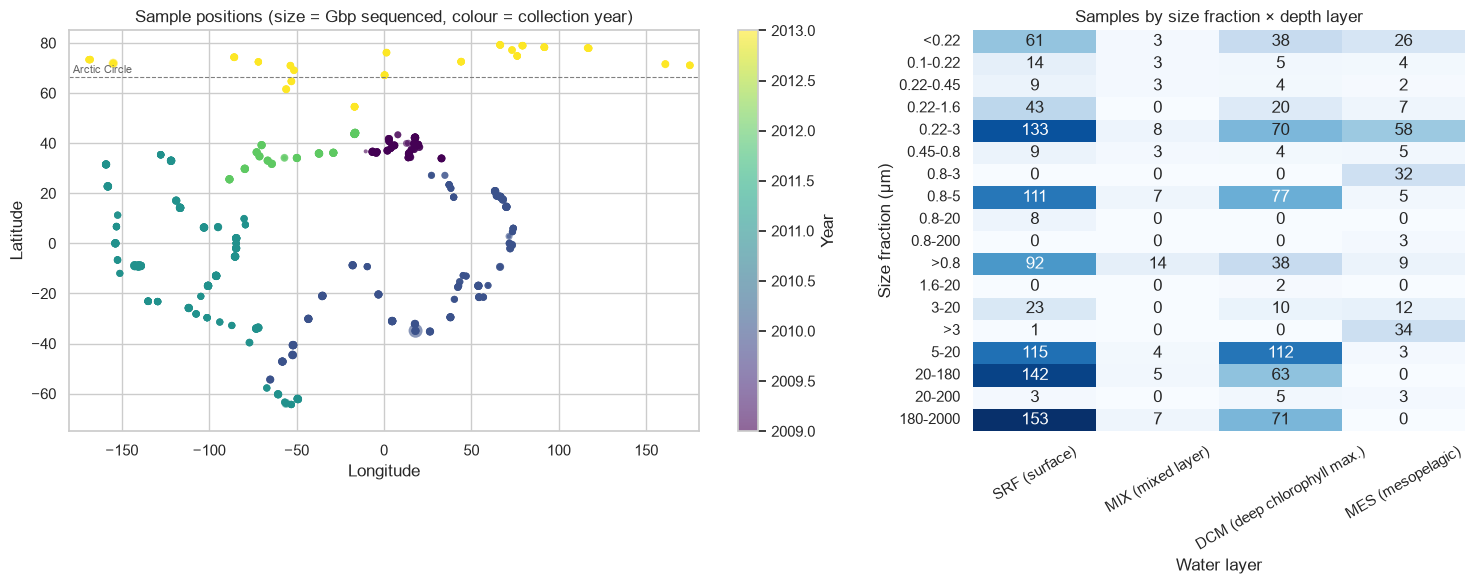

In [9]:
per_sample = runs.groupby("sample_accession").agg(
    Gbp=("Gbp", "sum"), runs=("run_accession", "size"), assays=("assay", "nunique")
)
geo = samples.set_index("sample_accession").join(per_sample).dropna(subset=["lat", "lon"])
print(
    f"{samples['station'].nunique()} stations; samples collected {samples['date'].min():%Y-%m} to "
    f"{samples['date'].max():%Y-%m}; {per_sample['assays'].gt(1).mean():.0%} of samples have more than one assay type"
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.6, 1]})
sc = axes[0].scatter(
    geo["lon"],
    geo["lat"],
    c=geo["date"].dt.year,
    cmap="viridis",
    s=8 + 3 * np.sqrt(geo["Gbp"]),
    alpha=0.6,
    edgecolor="none",
)
axes[0].axhline(66.56, color="0.5", lw=0.8, ls="--")
axes[0].text(-178, 68, "Arctic Circle", fontsize=8, color="0.4")
axes[0].set(
    xlim=(-180, 180),
    ylim=(-75, 85),
    xlabel="Longitude",
    ylabel="Latitude",
    title="Sample positions (size = Gbp sequenced, colour = collection year)",
)
fig.colorbar(sc, ax=axes[0], label="Year")
FRACTION_ORDER = sorted(samples["fraction"].dropna().unique(), key=fraction_key)
LAYER_ORDER = ["SRF (surface)", "MIX (mixed layer)", "DCM (deep chlorophyll max.)", "MES (mesopelagic)"]
grid = pd.crosstab(samples["fraction"], samples["layer"]).reindex(index=FRACTION_ORDER, columns=LAYER_ORDER)
sns.heatmap(grid, annot=True, fmt="d", cmap="Blues", ax=axes[1], cbar=False)
axes[1].set(xlabel="Water layer", ylabel="Size fraction (µm)", title="Samples by size fraction × depth layer")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURES / "ena_04_samples.png", dpi=150)

In [10]:
lag = runs.merge(samples[["sample_accession", "date"]], on="sample_accession", how="left")
lag["years_to_public"] = (lag["first_public"] - lag["date"]).dt.days / 365.25
lag.groupby("assay")["years_to_public"].describe()[["count", "min", "50%", "max"]].round(1)

,count,min,50%,max
assay,,,,
Amplicon (marker gene),2839.0,2.9,7.5,16.2
Metagenome,1634.0,2.5,5.0,11.1
Metatranscriptome,1399.0,4.0,6.2,10.0
Single-cell genome (WGA),126.0,3.3,5.8,7.1


## 7 · Q6 — Metadata quality audit

FAIR asks that data be *Findable* and *Interoperable*, which in practice means machine-readable fields and ontology
terms that resolve. Three checks: (a) how complete the run-level fields are; (b) whether ontology terms are real IDs or
templates such as `ENVO:xxxxxxxx`; (c) inconsistencies in the free text.

In [11]:
AUDIT = [
    "instrument_model",
    "lat",
    "lon",
    "depth",
    "environment_feature",
    "environment_material",
    "nominal_length",
    "collection_date",
    "country",
]
audit = completeness(runs.assign(nominal_length=runs["nominal_length"].replace(0, np.nan)), AUDIT)

placeholders = {
    col: runs[col].map(is_placeholder).mean() for col in ("environment_feature", "environment_material")
}
title_typos = studies[studies["study_title"].str.contains("Cicle", regex=False)]["study_title"].tolist()
print(
    "Share of runs whose ENVO term is a placeholder (ENVO:xxxx…):",
    {k: f"{v:.0%}" for k, v in placeholders.items()},
)
print("Instrument recorded as 'unspecified':", int((runs["instrument_model"] == "unspecified").sum()), "runs")
print("Study titles with a typo:", title_typos)
print("Distinct spellings of the material term:", runs["environment_material"].nunique())
print(
    "Sample records with structured collection_date / country:",
    f"{samples['collection_date'].notna().mean():.0%} / {samples['country'].notna().mean():.0%}",
)
audit.style.format({"filled": "{:.0%}"})

Share of runs whose ENVO term is a placeholder (ENVO:xxxx…): {'environment_feature': '27%', 'environment_material': '82%'}
Instrument recorded as 'unspecified': 48 runs
Study titles with a typo: ['Shotgun Sequencing of Tara Oceans Polar Cicle DNA samples corresponding to size fractions for prokaryotes.']
Distinct spellings of the material term: 6
Sample records with structured collection_date / country: 0% / 0%


,field,filled,empty_runs
0,collection_date,0%,6423
1,country,0%,6423
2,depth,93%,469
3,lat,93%,425
4,lon,93%,425
5,environment_feature,93%,425
6,environment_material,93%,425
7,nominal_length,95%,302
8,instrument_model,99%,48


## 8 · Findings

PRJEB402 is an umbrella over **22 sub-studies: 6,423 runs from 1,940 samples at 149 stations** (Sept 2009 – Oct 2013),
totalling **77.4 terabases** (66 TB of compressed FASTQ).

**Q1 · What was sequenced.** Counting runs and counting data give opposite pictures. **Amplicon** (marker-gene)
runs are 44 % of all runs but only **2 % of the bases**; **metagenomes** are 27 % of runs but **59 %** of the bases, and
metatranscriptomes 36 %. Any "how much data" statement needs to say which measure it uses.

**Q2 · Instruments.** One instrument dominates: the **Illumina HiSeq 2000 produced 70.7 of 77.4 Tbp (91 %)** from half
the runs. The project spans a decade of sequencing technology, from 454 pyrosequencing (99 runs) and the Genome
Analyzer IIx (1,258 runs, but < 1 Tbp) to HiSeq 4000 and NovaSeq. Bases per read (both mates combined) cluster at each instrument's read
configurations (e.g. 200 = 2×100 bp on the HiSeq 2000; up to 500 = 2×250 bp on the HiSeq 2500; ~350–600 bases on 454),
so instrument model alone is a useful QC sanity check.

**Q3 · Reads per run.** Median depth differs about 100-fold by assay: amplicon **1.6 M** reads, single-cell genomes 37 M,
metatranscriptomes 75 M, metagenomes **164 M**. **57 runs have < 100,000 reads** (36 amplicon, 18
metatranscriptome, 3 metagenome). These are candidates for exclusion before any reanalysis. 98 % of runs are paired-end.

**Q4 · Release timeline.** Data were released over **12 years (2013–2025)**. The median delay from sampling to public
release was **5.0 years for metagenomes, 6.2 for metatranscriptomes and 7.5 for amplicons**, 70 Genome Analyzer IIx runs only
became public in 2025, and the longest delay is 16 years. For a reuser, "the Tara Oceans
data" is a moving target, so analyses should record their retrieval date.

**Q5 · Sampling design.** The map traces the expedition route: Mediterranean (2009) → Indian Ocean and South Atlantic
(2010) → Pacific (2011) → North Atlantic (2012) → the 2013 **Arctic (Polar Circle)** leg. Most samples come from the **surface** and the **deep chlorophyll maximum**, with
consistent size fractions from viruses (< 0.22 µm) to small animals (180–2000 µm). **58 % of samples have more than one
assay type**, so DNA and RNA from the same water can be paired. That pairing makes the dataset powerful.

**Q6 · Metadata quality (FAIR).** The data are open, but the metadata is hard to find by machine:
* **Collection date and country are empty for 100 % of runs and samples.** Date, station, depth layer and size
  fraction exist only in free-text descriptions, in two formats. Regular expressions recover 88–92 % of them. A user who
  filters ENA by date or country will find **none** of Tara Oceans.
* **Ontology terms are templates:** 82 % of runs carry `ENVO:xxxxxxxx` instead of a real ID for the material, and 27 % for
  the environmental feature. These terms can't be resolved, so ontology-aware search misses them.
* **Inconsistent free text:** size fractions are written 22 different ways (18 after normalising `0.8->` / `>0.8` and
  similar), one sub-study title says "Polar *Cicle*", and 48 runs record the instrument as `unspecified`.
* **Search scope:** searching samples by project returns only 448 of the 1,940 samples that the runs reference. Starting
  from runs and looking samples up by accession is the reliable route.

**Take-away:** the ENA Portal API made a 6,000-run inventory a two-request job. The hard part of reuse is the metadata:
the most useful facts sit in prose rather than in searchable fields, which is exactly what FAIR's *Findable* and
*Interoperable* principles are meant to prevent.

## Reproducibility & FAIR notes
* **Source:** ENA Portal API, `result=read_run` and `result=sample` for umbrella project PRJEB402. The raw responses
  (with request URL and fetch time) are cached in `data/raw/api_cache/ena/` and are not committed (repository data policy).
* **Integrity checks:** run count = ENA's `/count`; every sample accession referenced by a run is returned.
* **Parsing is reported, not assumed:** the parse rate of each free-text field is printed, and unparsed values stay empty.
* **Re-run:** `make lab` → this notebook → *Run All* (EMBL-EBI DS kernel). The first run takes ~30 s.
* **Licence/terms:** ENA data are freely available without restriction ([ENA usage policy](https://www.ebi.ac.uk/ena/browser/about/policies)).
  Tara Oceans: Sunagawa et al., *Science* 348 (2015); Pesant et al., *Sci. Data* 2, 150023 (2015).